# 05 Modélisation

On classe les artistes de chaque cohorte selon leur probabilité d'une première sortie en major dans les 3 ans. Les modèles partent des 30 variables du notebook 03. Un A&R ne peut écouter qu'une centaine ou quelques centaines d'artistes par an, c'est donc le haut du classement qui compte.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, log_loss

sys.path.append("..")
from src.modelisation import (
    BOOSTING, COLONNES_PAR_FAMILLE, FORET, LOGISTIQUE, boosting, foret, intervalle_ecart, logistique, mesures, preparer,
)

table = pd.read_parquet("../data/features.parquet")
X, y = preparer(table)
t0 = table["t0"].to_numpy()
table.groupby("t0")["y"].agg(artistes="size", positifs="sum", taux="mean").round(4)

,artistes,positifs,taux
t0,,,
2014,41081,471,0.0115
2015,47075,520,0.0110
2016,51359,530,0.0103
2017,56812,587,0.0103
2018,61480,620,0.0101
2021,82372,719,0.0087


## 1. Découpage dans le temps

La cible d'une cohorte T0 regarde les sorties de T0 à T0 + 2. Au moment du test (T0 = 2021), les cohortes 2014 à 2018 ont toutes leur cible connue, la dernière finit en 2020. Pour reproduire ce décalage en validant sur T0 = 2018, on n'entraîne que sur les cohortes dont la cible finit avant 2018. Il ne reste que 2014 et 2015.

Entraîner aussi sur 2016 et 2017 ferait apprendre des passages en major de 2018 à 2020, souvent ceux des mêmes artistes que la validation.

In [2]:
positifs = table[table["y"]]
positifs_2018 = positifs.loc[positifs["t0"] == 2018, "artist"]
pd.Series({t: positifs_2018.isin(positifs.loc[positifs["t0"] == t, "artist"]).sum() for t in [2015, 2016, 2017]},
          name=f"positifs de 2018 (sur {len(positifs_2018)}) déjà positifs dans la cohorte")

2015      0
2016     98
2017    299
Name: positifs de 2018 (sur 620) déjà positifs dans la cohorte, dtype: int64

In [3]:
VALIDATION = t0 == 2018
decoupages = {}
for annees in [[2014, 2015], [2014, 2015, 2016], [2014, 2015, 2016, 2017]]:
    entrainement = np.isin(t0, annees)
    modele = boosting().fit(X[entrainement], y[entrainement])
    decoupages[f"entraînement {annees[0]} à {annees[-1]}"] = mesures(y[VALIDATION], modele.predict_proba(X[VALIDATION])[:, 1])
pd.DataFrame(decoupages).T.round(3)

,AUC PR,AUC ROC,précision@100,rappel@100,précision@500,rappel@500
entraînement 2014 à 2015,0.030,0.726,0.07,0.011,0.068,0.055
entraînement 2014 à 2016,0.033,0.758,0.06,0.010,0.072,0.058
entraînement 2014 à 2017,0.048,0.797,0.11,0.018,0.094,0.076


299 des 620 positifs de 2018 sont déjà positifs dans la cohorte 2017, et 98 dans la cohorte 2016. C'est le même passage en major, vu deux fois. Avec ces cohortes dans l'entraînement, l'AUC PR de validation passe de 0,030 à 0,048, un gain que le test ne pourra pas offrir. On entraîne donc sur 2014 et 2015 et on valide sur 2018. Le modèle retenu est ensuite réentraîné sur 2014 à 2018 pour le test.

## 2. Les variables en bref

Distributions et corrélations sont dans le notebook 04. Deux choses à garder en tête. Les comptes ont des queues lourdes (4 singles au 99e centile, 86 au maximum), ce qui gêne la régression logistique (partie 5). Et six paires de variables sont corrélées à plus de 0,8 en valeur absolue, elles se partageront l'importance par permutation (partie 10).

## 3. Mesures

In [4]:
ENTRAINEMENT = np.isin(t0, [2014, 2015])
X_ent, y_ent, X_val, y_val = X[ENTRAINEMENT], y[ENTRAINEMENT], X[VALIDATION], y[VALIDATION]
print(f"entraînement : {len(y_ent)} artistes, {y_ent.sum()} positifs ; validation : {len(y_val)} artistes, {y_val.sum()} positifs")
print(f"exactitude (accuracy) d'un modèle qui répond toujours non : {1 - y_val.mean():.2%}")

entraînement : 88156 artistes, 991 positifs ; validation : 61480 artistes, 620 positifs
exactitude (accuracy) d'un modèle qui répond toujours non : 98.99%


Avec 1,01 % de positifs, un modèle qui répond toujours non a 98,99 % d'exactitude et ne trouve personne. On mesure donc le classement.

- AUC PR (précision moyenne). Elle vaut le taux de positifs pour un classement au hasard, 0,010 ici, et 1 pour un classement parfait.
- AUC ROC, pour référence. Avec 99 % de négatifs, elle reste élevée même quand le haut du classement contient surtout des négatifs.
- Précision et rappel parmi les k premiers, pour k = 100 et 500. C'est ce que voit un A&R qui écoute k artistes. La précision est la part d'entre eux qui passe en major, le rappel la part des positifs qu'il trouve.
- Calibration, en partie 9.

## 4. Référence

Le hasard, puis une seule variable sans apprentissage, `label_tremplin`, qui est déjà un taux de passage en major (celui du meilleur label de l'artiste). Les artistes sans label connu reçoivent le taux de positifs de leurs semblables à l'entraînement.

In [5]:
sans_label = y_ent[X_ent["label_tremplin"].isna()].mean()
scores = {
    "hasard": np.random.default_rng(0).random(len(y_val)),
    "label_tremplin seul": X_val["label_tremplin"].fillna(sans_label).to_numpy(),
}
pd.DataFrame({nom: mesures(y_val, s) for nom, s in scores.items()}).T.round(3)

,AUC PR,AUC ROC,précision@100,rappel@100,précision@500,rappel@500
hasard,0.010,0.488,0.02,0.003,0.008,0.006
label_tremplin seul,0.017,0.554,0.11,0.018,0.050,0.040


`label_tremplin` seul fait 1,7 fois l'AUC PR du hasard (0,017 contre 0,010). Il place 11 positifs parmi les 100 premiers, là où le hasard en attend 1,0. C'est la barre à dépasser.

## 5. Régression logistique

Les valeurs manquantes sont remplacées par la médiane avec un indicateur, et les variables centrées réduites (z-score). Pays et type passent en one hot, les pays vus moins de 500 fois sont regroupés. On compare ensuite les rangs ramenés à une loi normale (`QuantileTransformer`) et la force de la pénalité (C = 1 / lambda). On teste aussi L1 contre L2, et le poids des classes.

In [6]:
reglages = {
    "z-score, C = 1": dict(),
    "rangs, C = 1": dict(quantiles=True),
    "rangs, C = 0,1": dict(quantiles=True, C=0.1),
    "rangs, C = 0,01": dict(quantiles=True, C=0.01),
    "rangs, C = 0,1, L1": dict(quantiles=True, C=0.1, l1_ratio=1.0),
    "rangs, C = 0,1, classes équilibrées": dict(quantiles=True, C=0.1, class_weight="balanced"),
}
logit = {}
for nom, reglage in reglages.items():
    modele = logistique(**reglage).fit(X_ent, y_ent)
    proba = modele.predict_proba(X_val)[:, 1]
    logit[nom] = mesures(y_val, proba) | {"proba moyenne": proba.mean(), "coefficients non nuls": (modele[-1].coef_ != 0).sum()}
pd.DataFrame.from_dict(logit, orient="index").round(3)

,AUC PR,AUC ROC,précision@100,rappel@100,précision@500,rappel@500,proba moyenne,coefficients non nuls
"z-score, C = 1",0.038,0.752,0.14,0.023,0.096,0.077,0.014,59
"rangs, C = 1",0.047,0.758,0.18,0.029,0.106,0.085,0.014,59
"rangs, C = 0,1",0.048,0.757,0.19,0.031,0.114,0.092,0.015,59
"rangs, C = 0,01",0.046,0.753,0.20,0.032,0.110,0.089,0.015,59
"rangs, C = 0,1, L1",0.047,0.755,0.19,0.031,0.108,0.087,0.015,38
"rangs, C = 0,1, classes équilibrées",0.047,0.759,0.21,0.034,0.100,0.081,0.430,59


Passer du z-score aux rangs fait monter l'AUC PR de 0,038 à 0,047, les extrêmes de la partie 2 ne dominent plus. Avec les rangs, C = 0,1 donne la meilleure AUC PR (0,048). C = 0,01 donne 0,046 et C = 1 donne 0,047. L1 ne garde que 38 coefficients sur 59 pour une AUC PR presque égale (0,047). Équilibrer les classes ne gagne rien (0,047) et fausse les probabilités, 43,0 % en moyenne pour 1,01 % de positifs. On garde les rangs, C = 0,1 et L2, sans poids de classe.

In [7]:
print(LOGISTIQUE)
modele = logistique(**LOGISTIQUE).fit(X_ent, y_ent)
scores["régression logistique"] = modele.predict_proba(X_val)[:, 1]

{'quantiles': True, 'C': 0.1}


## 6. Forêt aléatoire

300 arbres sur des tirages avec remise. Pays et type en codes entiers (label encoding), les valeurs manquantes laissées telles quelles. Le réglage qui compte est la taille minimale d'une feuille.

In [8]:
forets = {}
for feuille in [1, 10, 50, 200, 500]:
    modele = foret(n_estimators=300, min_samples_leaf=feuille).fit(X_ent, y_ent)
    forets[feuille] = {
        "AUC PR entraînement": average_precision_score(y_ent, modele.predict_proba(X_ent)[:, 1]),
        "AUC PR validation": average_precision_score(y_val, modele.predict_proba(X_val)[:, 1]),
    }
forets = pd.DataFrame(forets).T.rename_axis("min_samples_leaf")
forets.round(3)

,AUC PR entraînement,AUC PR validation
min_samples_leaf,,
1,0.962,0.024
10,0.500,0.034
50,0.164,0.036
200,0.081,0.036
500,0.063,0.034


Avec des feuilles d'un seul artiste, la forêt apprend l'entraînement par cœur (AUC PR 0,962) et classe mal la validation (0,024). À partir de 10 artistes par feuille, la validation plafonne entre 0,034 et 0,036. On garde la taille qui donne la meilleure AUC PR de validation, 50.

In [9]:
# FORET, rangé dans src/modelisation.py pour le notebook 06, est bien ce meilleur réglage
assert FORET == dict(n_estimators=300, min_samples_leaf=forets["AUC PR validation"].idxmax())
print(FORET)
modele = foret(**FORET).fit(X_ent, y_ent)
scores["forêt aléatoire"] = modele.predict_proba(X_val)[:, 1]

{'n_estimators': 300, 'min_samples_leaf': 50}


## 7. Gradient boosting

`HistGradientBoostingClassifier` construit les arbres l'un après l'autre, chacun corrige les erreurs des précédents. Il gère les valeurs manquantes et les catégories sans préparation. Comme AdaBoost, il surapprend si on le laisse tourner. On suit donc la perte (log loss) d'entraînement et de validation à chaque arbre ajouté.

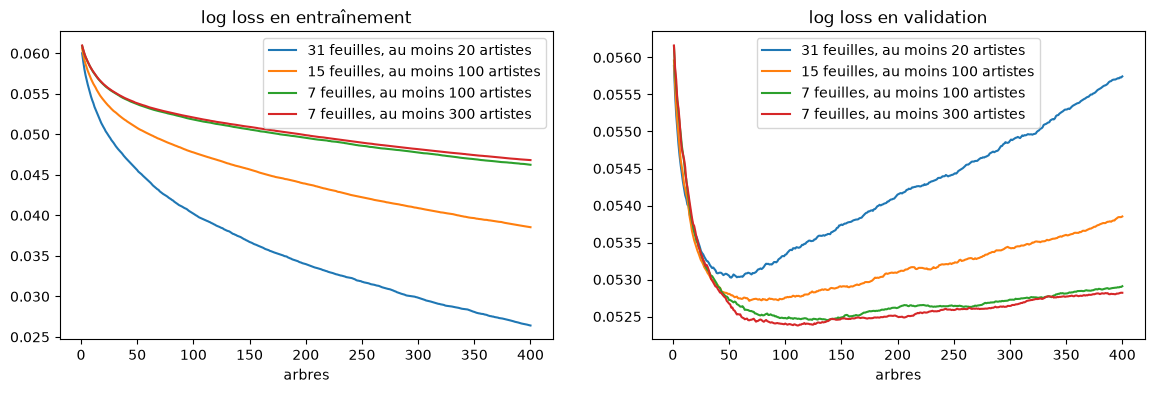

meilleur nombre d'arbres  log loss
31 20                         52   0.05303
15 100                        68   0.05271
7  100                       137   0.05245
   300                       111   0.05238

In [10]:
ARBRES = 400
pertes = {}
for feuilles, taille in [(31, 20), (15, 100), (7, 100), (7, 300)]:
    modele = boosting(learning_rate=0.05, max_iter=ARBRES, max_leaf_nodes=feuilles, min_samples_leaf=taille).fit(X_ent, y_ent)
    pertes[(feuilles, taille, "entraînement")] = [log_loss(y_ent, p[:, 1]) for p in modele.staged_predict_proba(X_ent)]
    pertes[(feuilles, taille, "validation")] = [log_loss(y_val, p[:, 1]) for p in modele.staged_predict_proba(X_val)]
pertes = pd.DataFrame(pertes, index=np.arange(1, ARBRES + 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for (feuilles, taille, jeu), courbe in pertes.items():
    courbe.plot(ax=axes[int(jeu == "validation")], label=f"{feuilles} feuilles, au moins {taille} artistes")
for ax, jeu in zip(axes, ["entraînement", "validation"]):
    ax.set(title=f"log loss en {jeu}", xlabel="arbres")
    ax.legend()
plt.show()

validation = pertes.xs("validation", axis=1, level=2)
pd.DataFrame({"meilleur nombre d'arbres": validation.idxmin(), "log loss": validation.min()}).round(5)

Avec 31 feuilles d'au moins 20 artistes, proche du réglage par défaut, la perte de validation remonte après 52 arbres. Celle d'entraînement continue de baisser, c'est le surapprentissage. Des arbres plus petits repoussent ce point, et les trois autres réglages descendent entre 0,0524 et 0,0527. On garde le minimum, 7 feuilles d'au moins 300 artistes et 111 arbres.

In [11]:
feuilles, taille = validation.min().idxmin()
arbres = validation[(feuilles, taille)].idxmin()
# BOOSTING, rangé dans src/modelisation.py pour le notebook 06, est bien ce meilleur réglage
assert BOOSTING == dict(learning_rate=0.05, max_iter=arbres, max_leaf_nodes=feuilles, min_samples_leaf=taille)
print(BOOSTING)
modele = boosting(**BOOSTING).fit(X_ent, y_ent)
scores["gradient boosting"] = modele.predict_proba(X_val)[:, 1]
print(f"artistes au-dessus du seuil 0,5 : {(scores['gradient boosting'] > 0.5).sum()}")

{'learning_rate': 0.05, 'max_iter': 111, 'max_leaf_nodes': 7, 'min_samples_leaf': 300}


artistes au-dessus du seuil 0,5 : 0


## 8. Comparaison sur la validation

In [12]:
pd.DataFrame({nom: mesures(y_val, s) for nom, s in scores.items()}).T.round(3)

,AUC PR,AUC ROC,précision@100,rappel@100,précision@500,rappel@500
hasard,0.010,0.488,0.02,0.003,0.008,0.006
label_tremplin seul,0.017,0.554,0.11,0.018,0.050,0.040
régression logistique,0.048,0.757,0.19,0.031,0.114,0.092
forêt aléatoire,0.036,0.752,0.09,0.015,0.094,0.076
gradient boosting,0.041,0.746,0.21,0.034,0.086,0.069


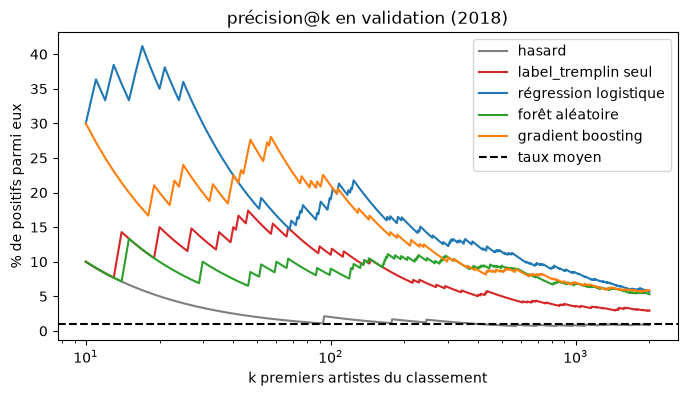

AUC PR logistique - boosting : intervalle à 95 % [-0.0031, 0.0180]


In [13]:
COULEURS = {"hasard": "tab:gray", "label_tremplin seul": "tab:red", "régression logistique": "tab:blue",
            "forêt aléatoire": "tab:green", "gradient boosting": "tab:orange"}


def courbe_precision(y_vrai, scores, titre):
    fig, ax = plt.subplots(figsize=(8, 4))
    k = np.arange(1, 2001)
    for nom, s in scores.items():
        ordre = np.argsort(-s, kind="stable")[:2000]
        ax.plot(k[9:], (100 * y_vrai[ordre].cumsum() / k)[9:], label=nom, color=COULEURS[nom])
    ax.axhline(100 * y_vrai.mean(), color="black", linestyle="--", label="taux moyen")
    ax.set(xscale="log", xlabel="k premiers artistes du classement", ylabel="% de positifs parmi eux", title=titre)
    ax.legend()
    plt.show()


courbe_precision(y_val, scores, "précision@k en validation (2018)")
bas, haut = intervalle_ecart(y_val, scores["régression logistique"], scores["gradient boosting"])
print(f"AUC PR logistique - boosting : intervalle à 95 % [{bas:.4f}, {haut:.4f}]")

Un seul an de validation peut favoriser un modèle par hasard. Second découpage avec le même décalage de 3 ans, entraînement sur 2014 et validation sur 2017.

In [14]:
candidats = {"régression logistique": logistique(**LOGISTIQUE), "forêt aléatoire": foret(**FORET), "gradient boosting": boosting(**BOOSTING)}


def auc_pr(annees, evaluation):
    """AUC PR de chaque candidat entraîné sur les cohortes `annees` et mesuré sur la cohorte `evaluation`."""
    entrainement, evalue = np.isin(t0, annees), t0 == evaluation
    return {nom: average_precision_score(y[evalue], clone(m).fit(X[entrainement], y[entrainement]).predict_proba(X[evalue])[:, 1])
            for nom, m in candidats.items()}


pd.DataFrame({"2014 vers 2017": auc_pr([2014], 2017), "2014 et 2015 vers 2018": auc_pr([2014, 2015], 2018)}).T.round(4)

,régression logistique,forêt aléatoire,gradient boosting
2014 vers 2017,0.0374,0.0340,0.0376
2014 et 2015 vers 2018,0.0479,0.0364,0.0409


Les trois modèles font 3,6 à 4,8 fois mieux que le hasard et plus de 2 fois mieux que `label_tremplin` seul. En 2018, la régression logistique est devant, avec une AUC PR de 0,048 contre 0,036 pour la forêt et 0,041 pour le boosting. Elle place 19 positifs parmi les 100 premiers et 57 parmi les 500 premiers. Sur le second découpage, elle fait jeu égal avec le boosting (0,0374 contre 0,0376) et devance la forêt (0,0340). L'écart avec le boosting en 2018 reste dans un intervalle qui contient 0, [-0,0031 ; 0,0180]. On retient donc le modèle le plus simple, la régression logistique.

Aucun artiste de la validation ne dépasse une probabilité de 0,5 avec le boosting. Le seuil par défaut ne signale personne, il se fixe ici par le nombre d'artistes que l'A&R peut écouter.

## 9. Calibration

Un A&R lit aussi la probabilité elle-même. Par dixième des artistes classés, on compare la probabilité moyenne annoncée au taux de positifs observé.

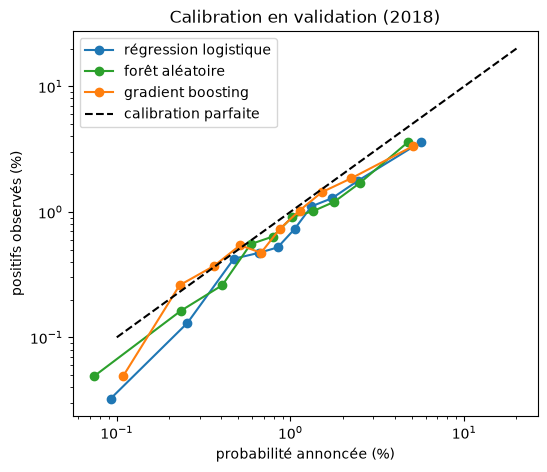

régression logistique    0.0145
forêt aléatoire          0.0135
gradient boosting        0.0127
observé                  0.0101
Name: probabilité moyenne en validation, dtype: float64

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
for nom in ["régression logistique", "forêt aléatoire", "gradient boosting"]:
    observe, annonce = calibration_curve(y_val, scores[nom], n_bins=10, strategy="quantile")
    ax.plot(100 * annonce, 100 * observe, marker="o", label=nom, color=COULEURS[nom])
ax.plot([0.1, 20], [0.1, 20], color="black", linestyle="--", label="calibration parfaite")
ax.set(xscale="log", yscale="log", xlabel="probabilité annoncée (%)", ylabel="positifs observés (%)",
       title="Calibration en validation (2018)")
ax.legend()
plt.show()

pd.Series({nom: scores[nom].mean() for nom in ["régression logistique", "forêt aléatoire", "gradient boosting"]} | {"observé": y_val.mean()},
          name="probabilité moyenne en validation").round(4)

La régression logistique annonce 1,45 % en moyenne pour 1,01 % de positifs observés. La forêt et le boosting annoncent 1,35 % et 1,27 %. Les trois courbes passent sous la diagonale presque partout, les trois modèles surestiment, la logistique un peu plus. Le taux de positifs baisse d'une cohorte à l'autre (1,12 % à l'entraînement), et label_tremplin monte (notebook 04).

## 10. Importance des variables et ablation par famille

L'importance par permutation, c'est la perte d'AUC PR en validation quand on mélange une variable. Deux variables corrélées se partagent leur importance, d'où aussi l'ablation, qui réentraîne le modèle sans une famille entière.

In [16]:
importances = {}
for nom in ["régression logistique", "gradient boosting"]:
    modele = clone(candidats[nom]).fit(X_ent, y_ent)
    permutation = permutation_importance(modele, X_val, y_val, scoring="average_precision", n_repeats=5, random_state=0)
    importances[nom] = pd.Series(permutation.importances_mean, index=X.columns)
importances = pd.DataFrame(importances)
importances.loc[importances.mean(axis=1).sort_values(ascending=False).index[:12]].round(4)

,régression logistique,gradient boosting
singles,0.0121,0.0119
pays,0.0060,0.0131
collaborateurs,0.0161,0.0012
label_tremplin,0.0149,0.0020
part_collaborateurs_major,0.0096,0.0067
type,0.0057,0.0067
labels,0.0083,0.0002
annees_actives,0.0070,-0.0001
editions_par_disque,0.0037,0.0019
anciennete,0.0029,0.0012


In [17]:
ablation = {}
for famille, colonnes in COLONNES_PAR_FAMILLE.items():
    gardees = X.columns.drop(colonnes)
    ligne = {"variables": len(colonnes)}
    for nom, court in [("régression logistique", "logistique"), ("gradient boosting", "boosting")]:
        modele = clone(candidats[nom]).fit(X_ent[gardees], y_ent)
        sans = modele.predict_proba(X_val[gardees])[:, 1]
        bas, haut = intervalle_ecart(y_val, scores[nom], sans)
        ligne[f"perte {court}"] = round(average_precision_score(y_val, scores[nom]) - average_precision_score(y_val, sans), 4)
        ligne[f"intervalle {court}"] = f"[{bas:.4f}, {haut:.4f}]"
    ablation[famille] = ligne
pd.DataFrame(ablation).T

,variables,perte logistique,intervalle logistique,perte boosting,intervalle boosting
activité,8,0.0086,"[0.0034, 0.0135]",0.0036,"[-0.0012, 0.0104]"
traction,3,0.0013,"[-0.0009, 0.0038]",0.0004,"[-0.0027, 0.0035]"
documentation,2,-0.0003,"[-0.0012, 0.0006]",-0.0015,"[-0.0043, 0.0012]"
label,3,0.0017,"[-0.0010, 0.0047]",-0.0012,"[-0.0069, 0.0046]"
proximité,4,0.0067,"[-0.0001, 0.0150]",0.0,"[0.0000, 0.0000]"
réseau,5,0.0007,"[-0.0036, 0.0048]",0.0059,"[0.0003, 0.0130]"
profil,4,0.0071,"[0.0034, 0.0120]",0.0056,"[-0.0004, 0.0126]"
marché,1,-0.0001,"[-0.0014, 0.0011]",-0.0012,"[-0.0045, 0.0018]"


Pour la régression logistique, deux familles ont une perte dont l'intervalle est au-dessus de 0, l'activité (0,0086) et le profil (0,0071). La proximité des majors est à la limite (0,0067, intervalle [-0,0001 ; 0,0150]), la traction n'apporte plus rien de net (0,0013). collaborateurs et `label_tremplin` sont ses variables les plus importantes par permutation (0,0161 et 0,0149). Pourtant, retirer la famille réseau ne coûte que 0,0007, et la famille label 0,0017, intervalles contenant 0. Réentraîné sans elles, le modèle compense avec d'autres variables.

Le boosting ne perd nettement qu'avec le réseau (0,0059). L'activité et le profil sont à la limite (0,0036 et 0,0056, intervalles contenant 0). Sans la proximité, il ne perd rien (0,0000), il ne s'en sert pas. Il s'appuie surtout sur `pays` et `singles` (0,0131 et 0,0119). La documentation et le marché n'apportent rien aux deux modèles, pertes négatives ou nulles et intervalles autour de 0. On pourrait les retirer sans perte mesurable.

## 11. Test sur la cohorte 2021

Les réglages sont fixés. On réentraîne sur les cohortes 2014 à 2018, dont la cible finit au plus tard en 2020, et on mesure sur 2021.

In [18]:
FINAL, TEST = t0 <= 2018, t0 == 2021
X_fin, y_fin, X_test, y_test = X[FINAL], y[FINAL], X[TEST], y[TEST]
finaux = {"label_tremplin seul": X_test["label_tremplin"].fillna(y_fin[X_fin["label_tremplin"].isna()].mean()).to_numpy()}
for nom, modele in candidats.items():
    finaux[nom] = clone(modele).fit(X_fin, y_fin).predict_proba(X_test)[:, 1]
print(f"test : {len(y_test)} artistes, {y_test.sum()} positifs ({y_test.mean():.2%}), entraînement : {y_fin.mean():.2%} de positifs")
pd.DataFrame({nom: mesures(y_test, s) | {"proba moyenne": s.mean()} for nom, s in finaux.items()}).T.round(4)

test : 82372 artistes, 719 positifs (0.87%), entraînement : 1.06% de positifs


,AUC PR,AUC ROC,précision@100,rappel@100,précision@500,rappel@500,proba moyenne
label_tremplin seul,0.0178,0.6150,0.09,0.0125,0.060,0.0417,0.0099
régression logistique,0.0500,0.7696,0.21,0.0292,0.148,0.1029,0.0144
forêt aléatoire,0.0620,0.7768,0.26,0.0362,0.162,0.1127,0.0143
gradient boosting,0.0508,0.7631,0.18,0.0250,0.120,0.0834,0.0144


In [19]:
for nom in ["forêt aléatoire", "gradient boosting"]:
    bas, haut = intervalle_ecart(y_test, finaux[nom], finaux["régression logistique"])
    print(f"AUC PR {nom} - logistique en test : intervalle à 95 % [{bas:.4f}, {haut:.4f}]")

AUC PR forêt aléatoire - logistique en test : intervalle à 95 % [0.0011, 0.0214]


AUC PR gradient boosting - logistique en test : intervalle à 95 % [-0.0085, 0.0117]


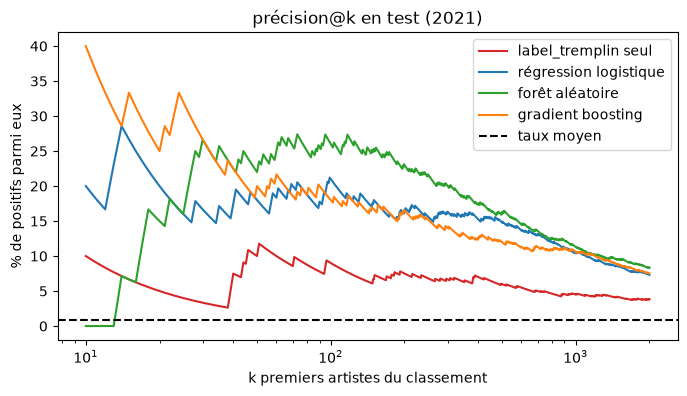

In [20]:
courbe_precision(y_test, finaux, "précision@k en test (2021)")

Le modèle retenu, la régression logistique, obtient en 2021 une AUC PR de 0,050, 5,7 fois le taux de positifs (0,87 %). Parmi les 500 artistes qu'il classe en tête, 14,8 % sont passés en major dans les 3 ans, 17 fois le taux moyen. Il y en a 21 parmi les 100 premiers. Ses probabilités sont trop hautes, 1,44 % en moyenne pour 0,87 % observés. En cause, le taux de positifs qui baisse d'une cohorte à l'autre (1,15 % en 2014, 1,06 % sur l'entraînement). Et label_tremplin monte (notebook 04).

En 2021 pourtant, la forêt classe mieux que la logistique (0,062, écart dont l'intervalle [0,0011 ; 0,0214] est au-dessus de 0). Le boosting fait jeu égal avec elle (0,051, intervalle [-0,0085 ; 0,0117]).

## 12. Pourquoi l'ordre change en 2021

Analyse faite après le test. Elle ne change pas le modèle retenu. On mesure les trois modèles entraînés sur 2014 et 2015, en 2018 puis en 2021. Puis on les entraîne sur 2014 à 2018.

In [21]:
pd.DataFrame({
    "2014 et 2015 vers 2018": auc_pr([2014, 2015], 2018),
    "2014 et 2015 vers 2021": auc_pr([2014, 2015], 2021),
    "2014 à 2018 vers 2021": auc_pr([2014, 2015, 2016, 2017, 2018], 2021),
}).T.round(4)

,régression logistique,forêt aléatoire,gradient boosting
2014 et 2015 vers 2018,0.0479,0.0364,0.0409
2014 et 2015 vers 2021,0.0471,0.0411,0.0348
2014 à 2018 vers 2021,0.0500,0.0620,0.0508


Entraînés sur les mêmes cohortes 2014 et 2015, les modèles gardent la logistique en tête en 2018 comme en 2021 (0,0479 puis 0,0471). La cohorte 2021 n'inverse donc pas l'ordre à elle seule, c'est l'entraînement sur 2014 à 2018 qui le change. Avec trois cohortes de plus, la forêt gagne 0,021 d'AUC PR en 2021 et le boosting 0,016, la logistique seulement 0,003. Les arbres profitent plus des données en plus, ce que la validation, entraînée sur deux cohortes, ne pouvait pas montrer.

Une partie de l'écart en 2021 se voit aussi sans la cible, dans `pays_de_sortie`. Cette variable vient de `release_country` et n'a pas de date (notebook 04). On compte par cohorte les artistes à plus de 10 pays de sortie, puis on mesure les modèles de la partie 11 sans eux.

In [22]:
large = (table["pays_de_sortie"] > 10).to_numpy()
print("artistes à plus de 10 pays de sortie :", pd.Series(large).groupby(t0).sum().to_dict())
large_test = large[TEST]
print(f"positifs en 2021 : {y_test[large_test].mean():.2%} chez ces artistes, {y_test[~large_test].mean():.2%} chez les autres")
for nom in ["forêt aléatoire", "gradient boosting"]:
    bas, haut = intervalle_ecart(y_test[~large_test], finaux[nom][~large_test], finaux["régression logistique"][~large_test])
    print(f"AUC PR {nom} - logistique sans ces artistes : intervalle à 95 % [{bas:.4f}, {haut:.4f}]")
pd.DataFrame({nom: {
    "part dans les 500 premiers": large_test[np.argsort(-finaux[nom], kind="stable")[:500]].mean(),
    "AUC PR sans ces artistes": average_precision_score(y_test[~large_test], finaux[nom][~large_test]),
} for nom in candidats}).T.round(4)

artistes à plus de 10 pays de sortie : {2014: 18, 2015: 28, 2016: 31, 2017: 38, 2018: 47, 2021: 1478}
positifs en 2021 : 5.89% chez ces artistes, 0.78% chez les autres


AUC PR forêt aléatoire - logistique sans ces artistes : intervalle à 95 % [-0.0002, 0.0200]


AUC PR gradient boosting - logistique sans ces artistes : intervalle à 95 % [-0.0128, 0.0031]


,part dans les 500 premiers,AUC PR sans ces artistes
régression logistique,0.226,0.0378
forêt aléatoire,0.456,0.0471
gradient boosting,0.542,0.0354


Les artistes à plus de 10 pays de sortie sont 18 en 2014, 47 en 2018 et 1 478 en 2021. Ils sont donc presque absents de l'entraînement et de la validation. En 2021, ils passent plus souvent en major que les autres, 5,89 % contre 0,78 %. Le boosting en met 54,2 % dans ses 500 premiers, la forêt 45,6 % et la logistique 22,6 %. Sans eux, la forêt reste devant la logistique (AUC PR 0,0471 contre 0,0378), mais l'intervalle touche 0 ([-0,0002 ; 0,0200]). Le boosting passe derrière (0,0354, intervalle [-0,0128 ; 0,0031]). Une partie de l'avance des arbres en 2021 tient donc à ces artistes.

Un modèle choisi sur les cohortes passées doit donc être revalidé à chaque nouvelle cohorte. On compare aussi la distribution des variables, qui se lit avant la cible. Ici, la forêt est celle qui a le mieux résisté.

## 13. Moyenne logistique + forêt

Idée venue après le test, où la forêt classait mieux que la logistique. On fait la moyenne des probabilités des deux modèles (`VotingClassifier`, vote souple). On la juge d'abord sur les deux validations, sans regarder 2021.

In [23]:
moyenne = VotingClassifier([("logistique", logistique(**LOGISTIQUE)), ("forêt", foret(**FORET))], voting="soft")
validations = {}
for annees, evaluation in [([2014], 2017), ([2014, 2015], 2018)]:
    entrainement, evalue = np.isin(t0, annees), t0 == evaluation
    s_moyenne = clone(moyenne).fit(X[entrainement], y[entrainement]).predict_proba(X[evalue])[:, 1]
    s_logistique = clone(candidats["régression logistique"]).fit(X[entrainement], y[entrainement]).predict_proba(X[evalue])[:, 1]
    bas, haut = intervalle_ecart(y[evalue], s_moyenne, s_logistique)
    print(f"validation {evaluation}, AUC PR moyenne - logistique : intervalle à 95 % [{bas:.4f}, {haut:.4f}]")
    validations[f"logistique, {evaluation}"] = mesures(y[evalue], s_logistique)
    validations[f"moyenne, {evaluation}"] = mesures(y[evalue], s_moyenne)
pd.DataFrame(validations).T.round(4)

validation 2017, AUC PR moyenne - logistique : intervalle à 95 % [0.0011, 0.0034]


validation 2018, AUC PR moyenne - logistique : intervalle à 95 % [0.0004, 0.0046]


,AUC PR,AUC ROC,précision@100,rappel@100,précision@500,rappel@500
"logistique, 2017",0.0374,0.7314,0.09,0.0153,0.086,0.0733
"moyenne, 2017",0.0396,0.7398,0.09,0.0153,0.092,0.0784
"logistique, 2018",0.0479,0.7573,0.19,0.0306,0.114,0.0919
"moyenne, 2018",0.0502,0.7651,0.18,0.0290,0.116,0.0935


La moyenne est devant la logistique sur les deux validations, avec un intervalle d'écart au-dessus de 0. Son AUC PR fait 0,0396 contre 0,0374 en 2017, et 0,0502 contre 0,0479 en 2018. Elle devance aussi le boosting et la forêt (partie 8). En 2018, elle place 18 positifs parmi les 100 premiers et 58 parmi les 500 premiers, contre 19 et 57 pour la logistique.

In [24]:
s_moyenne = clone(moyenne).fit(X_fin, y_fin).predict_proba(X_test)[:, 1]
for nom in ["régression logistique", "forêt aléatoire"]:
    bas, haut = intervalle_ecart(y_test, s_moyenne, finaux[nom])
    print(f"AUC PR moyenne - {nom} en test : intervalle à 95 % [{bas:.4f}, {haut:.4f}]")
comparaison = {nom: finaux[nom] for nom in ["régression logistique", "forêt aléatoire"]} | {"moyenne": s_moyenne}
pd.DataFrame({nom: mesures(y_test, s) | {"proba moyenne": s.mean()} for nom, s in comparaison.items()}).T.round(4)

AUC PR moyenne - régression logistique en test : intervalle à 95 % [0.0071, 0.0131]


AUC PR moyenne - forêt aléatoire en test : intervalle à 95 % [-0.0092, 0.0068]


,AUC PR,AUC ROC,précision@100,rappel@100,précision@500,rappel@500,proba moyenne
régression logistique,0.0500,0.7696,0.21,0.0292,0.148,0.1029,0.0144
forêt aléatoire,0.0620,0.7768,0.26,0.0362,0.162,0.1127,0.0143
moyenne,0.0598,0.7832,0.19,0.0264,0.166,0.1154,0.0143


En 2021, la moyenne obtient une AUC PR de 0,0598, au-dessus de la logistique (intervalle [0,0071 ; 0,0131]). Elle ne s'écarte pas nettement de la forêt (0,0620, intervalle [-0,0092 ; 0,0068]). Parmi ses 500 premiers artistes, 16,6 % passent en major dans les 3 ans, 19 fois le taux moyen. Ce chiffre est un peu optimiste, puisque l'idée vient du test.

Première sur les deux validations et deuxième en 2021, la moyenne est le candidat le plus sûr pour la cohorte suivante.